# Lab 3: Volatility Estimation, VaR and Scenario Analysis — IndusInd Bank (INDUSINDBK.NS)

## Task 1: Stock Selection, Liquidity and Data

In [18]:
# [SETUP] imports & config
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from arch import arch_model
from statsmodels.stats.diagnostic import het_arch
from scipy.optimize import minimize_scalar

ticker = "INDUSINDBK.NS"
start_date = "2020-06-01"
end_date = "2026-11-13"
var_window = 200

windows = [21, 50, 100, 200]
lam = 0.94

In [6]:
data = yf.download(
    ticker,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)
data = data[data["Volume"].squeeze() > 0]

price = data["Close"].squeeze()
volume = data["Volume"].squeeze()

returns = price.pct_change().dropna()
var_returns = returns.iloc[-var_window:]

In [9]:
# [T1] liquidity: turnover price impact (TPI)
tk = yf.Ticker(ticker)
shares_out = tk.get_shares_full(start=start_date, end=end_date)
shares_out.index = shares_out.index.tz_localize(None).normalize()
shares_out = shares_out[~shares_out.index.duplicated(keep="last")].sort_index()
shares_out = shares_out.reindex(shares_out.index.union(volume.index)).ffill().reindex(volume.index)

turnover = volume / shares_out
tpi = returns.abs() / turnover

turnover_var = turnover.loc[var_returns.index]
tpi_var = tpi.loc[var_returns.index]

print(f"Window: {tpi_var.index.min().date()} to {tpi_var.index.max().date()} ({len(tpi_var)} days)")
print("Missing share counts in window:", shares_out.loc[var_returns.index].isna().sum())
print(f"Mean daily turnover ratio: {turnover_var.mean()*100:.3f}%")
print(f"Mean TPI: {tpi_var.mean():.4f}")
print(f"Median TPI: {tpi_var.median():.4f}")

Window: 2026-01-20 to 2026-11-12 (200 days)
Missing share counts in window: 0
Mean daily turnover ratio: 0.359%
Mean TPI: 4.8750
Median TPI: 4.2237


In [10]:
# [T1] liquidity: peer benchmark (ICICI Bank)
peer = "ICICIBANK.NS"
peer_data = yf.download(peer, start=start_date, end=end_date, auto_adjust=True, progress=False)
peer_data = peer_data[peer_data["Volume"].squeeze() > 0]
peer_volume = peer_data["Volume"].squeeze()
peer_returns = peer_data["Close"].squeeze().pct_change().dropna()

peer_shares = yf.Ticker(peer).get_shares_full(start=start_date, end=end_date)
peer_shares.index = peer_shares.index.tz_localize(None).normalize()
peer_shares = peer_shares[~peer_shares.index.duplicated(keep="last")].sort_index()
peer_shares = peer_shares.reindex(peer_shares.index.union(peer_volume.index)).ffill().reindex(peer_volume.index)

peer_turnover = peer_volume / peer_shares
peer_tpi = peer_returns.abs() / peer_turnover
peer_turnover_var = peer_turnover.reindex(var_returns.index)
peer_tpi_var = peer_tpi.reindex(var_returns.index)

print("Missing peer days in window:", peer_tpi_var.isna().sum())
print("Peer shares outstanding in window:", peer_shares.reindex(var_returns.index).min(), "to", peer_shares.reindex(var_returns.index).max())
print(pd.DataFrame({
    "Mean turnover (%)": [turnover_var.mean() * 100, peer_turnover_var.mean() * 100],
    "Mean TPI": [tpi_var.mean(), peer_tpi_var.mean()],
    "Median TPI": [tpi_var.median(), peer_tpi_var.median()],
}, index=[ticker, peer]).round(4))

Missing peer days in window: 0
Peer shares outstanding in window: 7152180992.0 to 7180851934.0
               Mean turnover (%)  Mean TPI  Median TPI
INDUSINDBK.NS             0.3590    4.8750      4.2237
ICICIBANK.NS              0.2086    5.3581      4.4888


## Task 2: Volatility Estimation and Analysis

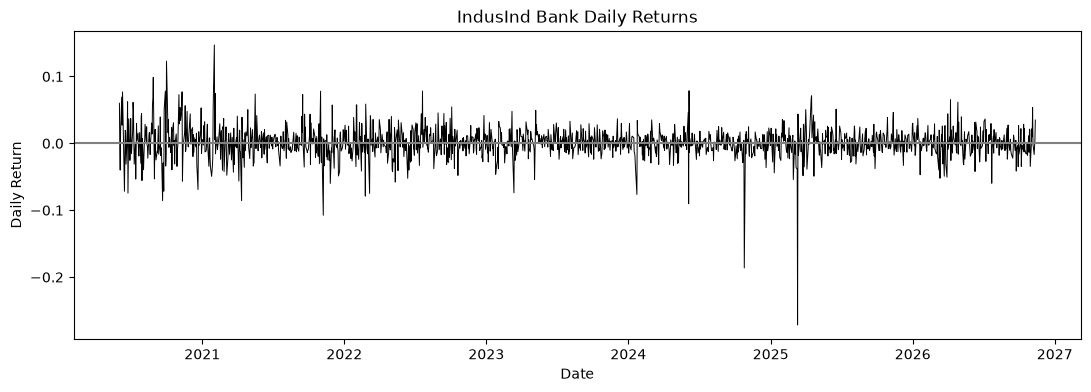

In [14]:
# [T2] daily returns plot
plt.figure(figsize=(13, 4))
plt.plot(returns, color="black", linewidth=0.7)
plt.axhline(0, color="grey")
plt.title("IndusInd Bank Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.show()

In [15]:
# [T2] rolling historical volatility
historical_vols = {}
for window in windows:
    historical_vols[window] = returns.shift(1).rolling(window).std()

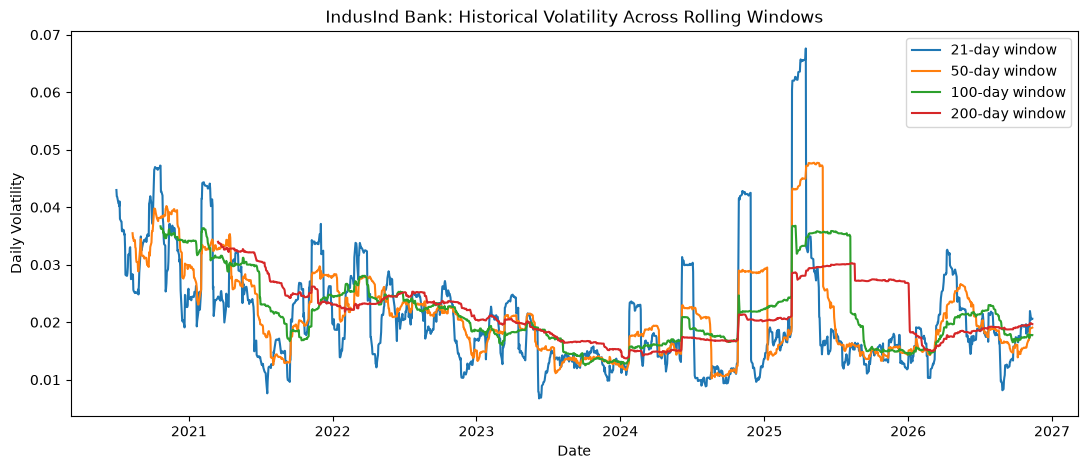

In [16]:
# [T2] rolling historical volatility plot
plt.figure(figsize=(13, 5))
for window in windows:
    plt.plot(historical_vols[window], label=f"{window}-day window")
plt.title("IndusInd Bank: Historical Volatility Across Rolling Windows")
plt.xlabel("Date")
plt.ylabel("Daily Volatility")
plt.legend()
plt.show()

In [19]:
# [T2] EWMA volatility
ewma_var = returns.shift(1).pow(2).ewm(alpha=1 - lam, adjust=False).mean()
ewma_vol = np.sqrt(ewma_var)

In [20]:
# [T2] EWMA lambda by maximum likelihood
def ewma_neg_loglik(l):
    v = returns.shift(1).pow(2).ewm(alpha=1 - l, adjust=False).mean()
    v, r = v.iloc[1:], returns.iloc[1:]
    return np.sum(np.log(v) + r**2 / v)

opt = minimize_scalar(ewma_neg_loglik, bounds=(0.80, 0.999), method="bounded")
lam_mle = opt.x
ewma_vol_mle = np.sqrt(returns.shift(1).pow(2).ewm(alpha=1 - lam_mle, adjust=False).mean())

print("MLE lambda:", round(lam_mle, 4))
print("Neg log-lik at 0.94:", round(ewma_neg_loglik(lam), 2), "| at MLE:", round(ewma_neg_loglik(lam_mle), 2))

MLE lambda: 0.8756
Neg log-lik at 0.94: -10429.01 | at MLE: -10470.74


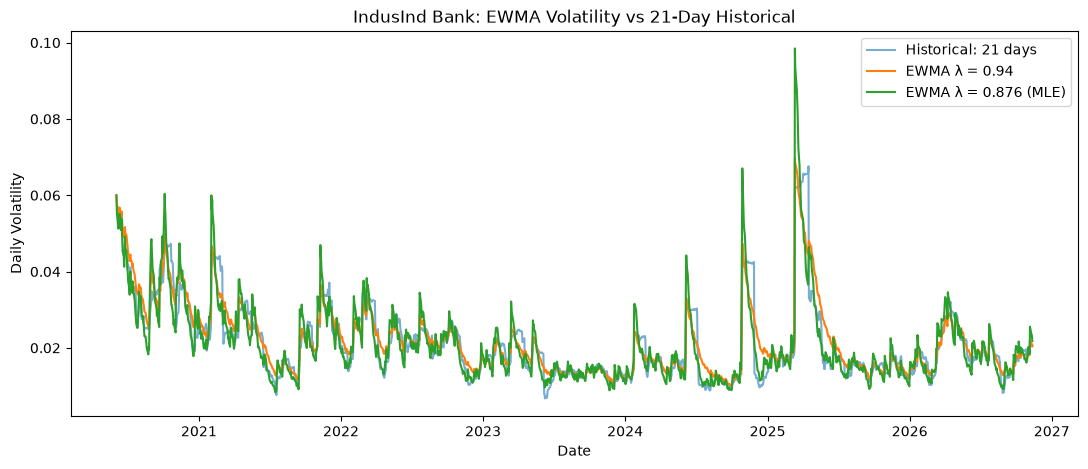

In [21]:
# [T2] EWMA plot
plt.figure(figsize=(13, 5))
plt.plot(historical_vols[21], label="Historical: 21 days", alpha=0.6)
plt.plot(ewma_vol, label=f"EWMA λ = {lam}")
plt.plot(ewma_vol_mle, label=f"EWMA λ = {lam_mle:.3f} (MLE)")
plt.title("IndusInd Bank: EWMA Volatility vs 21-Day Historical")
plt.xlabel("Date")
plt.ylabel("Daily Volatility")
plt.legend()
plt.show()

In [23]:
# [T2] ARCH LM test
arch_test = het_arch(returns * 100, nlags=12)
print("LM statistic:", round(arch_test[0], 2))
print("LM p-value:", arch_test[1])

LM statistic: 9.72
LM p-value: 0.6407409841100455


c:\Users\Parth\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [27]:
# [T2] ARCH LM test robustness
lo, hi = returns.quantile([0.01, 0.99])
returns_w = returns.clip(lower=lo, upper=hi)

rows = []
for lags in [1, 5, 12]:
    raw = het_arch(returns * 100, nlags=lags)
    win = het_arch(returns_w * 100, nlags=lags)
    rows.append([lags, raw[0], raw[1], win[0], win[1]])

print(pd.DataFrame(rows, columns=["Lags", "LM (raw)", "p (raw)", "LM (winsorized)", "p (winsorized)"]).round(4).to_string(index=False))
print(f"Winsorization bounds: {lo:.4f} to {hi:.4f} | days clipped: {(returns != returns_w).sum()}")

 Lags  LM (raw)  p (raw)  LM (winsorized)  p (winsorized)
    1    5.2281   0.0222          80.8520             0.0
    5    8.3588   0.1375         131.7279             0.0
   12    9.7174   0.6407         135.4752             0.0
Winsorization bounds: -0.0580 to 0.0673 | days clipped: 32


c:\Users\Parth\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [24]:
# [T2] GARCH(1,1) normal
garch_model = arch_model(
    returns * 100,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal",
    rescale=False
)
garch_res = garch_model.fit(disp="off")
garch_vol = garch_res.conditional_volatility / 100

print(garch_res.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:          INDUSINDBK.NS   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3486.49
Distribution:                  Normal   AIC:                           6980.97
Method:            Maximum Likelihood   BIC:                           7002.48
                                        No. Observations:                 1597
Date:                Fri, Nov 13 2026   Df Residuals:                     1596
Time:                        20:58:12   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1260  5.595e-02      2.251  2.437e-02 [1.629e-0

In [25]:
# [T2] GARCH(1,1) persistence
omega = garch_res.params["omega"]
alpha = garch_res.params["alpha[1]"]
beta = garch_res.params["beta[1]"]
persistence = alpha + beta

print("Alpha:", round(alpha, 4), "| Beta:", round(beta, 4), "| Persistence:", round(persistence, 4))
print("Half-life (days):", round(np.log(0.5) / np.log(persistence), 1))
print("Long-run daily vol:", round(np.sqrt(omega / (1 - persistence)) / 100, 4))

Alpha: 0.2772 | Beta: 0.6522 | Persistence: 0.9295
Half-life (days): 9.5
Long-run daily vol: 0.0299


In [28]:
# [T2] GARCH extensions
garch_t_res = arch_model(
    returns * 100, mean="Constant", vol="GARCH",
    p=1, q=1, dist="t", rescale=False
).fit(disp="off")

gjr_t_res = arch_model(
    returns * 100, mean="Constant", vol="GARCH",
    p=1, o=1, q=1, dist="t", rescale=False
).fit(disp="off")

garch_t_vol = garch_t_res.conditional_volatility / 100
gjr_t_vol = gjr_t_res.conditional_volatility / 100

print(garch_t_res.summary())
print(gjr_t_res.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                INDUSINDBK.NS   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -3351.92
Distribution:      Standardized Student's t   AIC:                           6713.84
Method:                  Maximum Likelihood   BIC:                           6740.72
                                              No. Observations:                 1597
Date:                      Fri, Nov 13 2026   Df Residuals:                     1596
Time:                              21:02:25   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
mu     

In [29]:
# [T2] GARCH model comparison
def garch_summary(name, res):
    p = res.params
    gamma = p.get("gamma[1]", 0.0)
    pers = p["alpha[1]"] + p["beta[1]"] + gamma / 2
    vol = res.conditional_volatility / 100
    return {
        "Model": name,
        "Log-lik": res.loglikelihood,
        "AIC": res.aic,
        "BIC": res.bic,
        "alpha": p["alpha[1]"],
        "gamma": gamma,
        "beta": p["beta[1]"],
        "nu": p.get("nu", np.nan),
        "Persistence": pers,
        "Half-life (days)": np.log(0.5) / np.log(pers),
        "Long-run vol": np.sqrt(p["omega"] / (1 - pers)) / 100,
        "Peak vol": vol.max(),
        "Peak date": vol.idxmax().date(),
        "Latest vol": vol.iloc[-1],
        "Converged": res.convergence_flag == 0,
    }

garch_table = pd.DataFrame([
    garch_summary("GARCH(1,1)-N", garch_res),
    garch_summary("GARCH(1,1)-t", garch_t_res),
    garch_summary("GJR-GARCH(1,1)-t", gjr_t_res),
]).set_index("Model")

print(garch_table.round(4).T)

Model            GARCH(1,1)-N GARCH(1,1)-t GJR-GARCH(1,1)-t
Log-lik            -3486.4858    -3351.921       -3351.7049
AIC                 6980.9716     6713.842        6715.4098
BIC                 7002.4751    6740.7214        6747.6651
alpha                  0.2772       0.1646           0.1518
gamma                     0.0          0.0           0.0336
beta                   0.6522       0.7235           0.7196
nu                        NaN       4.1025           4.1009
Persistence            0.9295       0.8881           0.8883
Half-life (days)       9.4772       5.8391            5.852
Long-run vol           0.0299       0.0236           0.0237
Peak vol               0.1461       0.1131           0.1199
Peak date          2025-03-12   2025-03-12       2025-03-12
Latest vol             0.0223       0.0222           0.0219
Converged                True         True             True


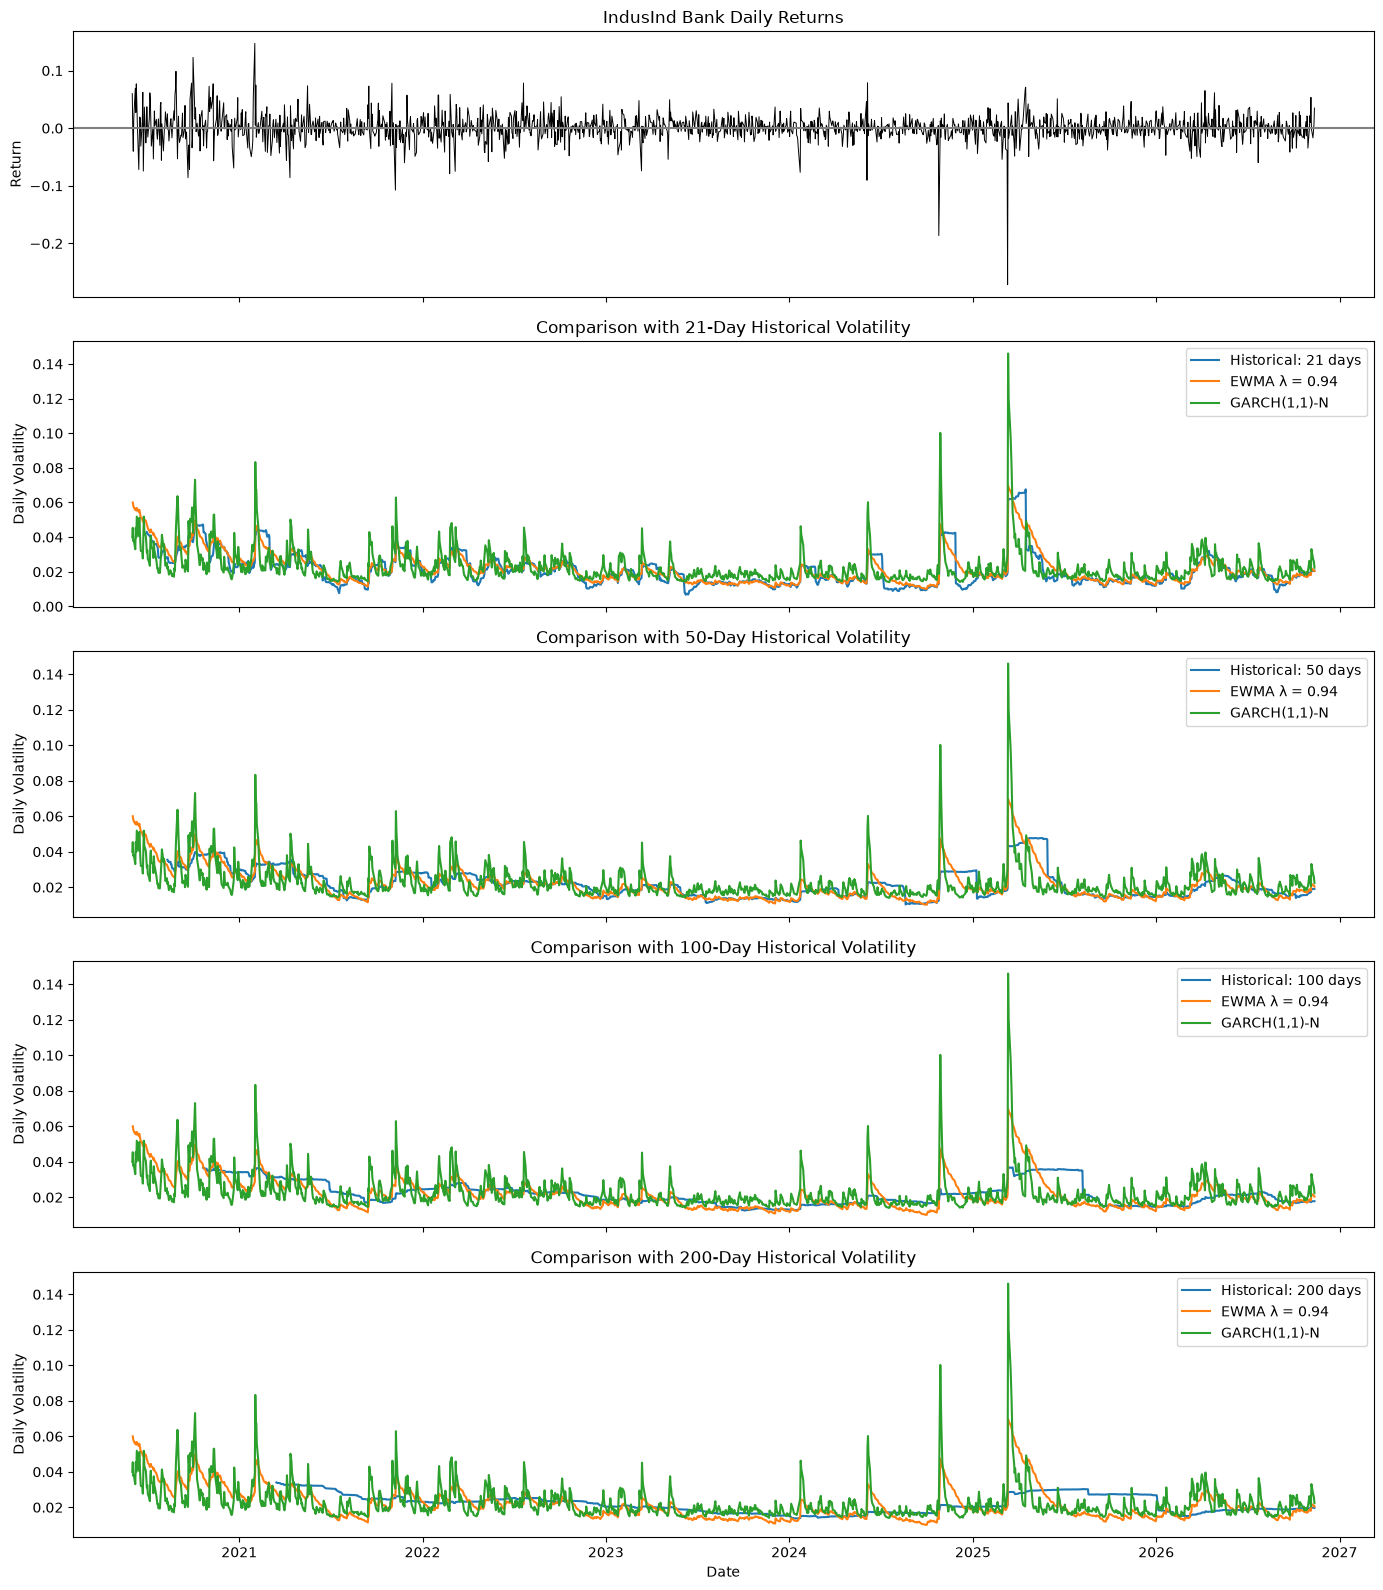

In [30]:
# [T2] volatility comparison (notebook layout)
fig, axes = plt.subplots(5, 1, figsize=(14, 16), sharex=True)

axes[0].plot(returns, color="black", linewidth=0.7)
axes[0].axhline(0, color="grey")
axes[0].set_title("IndusInd Bank Daily Returns")
axes[0].set_ylabel("Return")

for ax, window in zip(axes[1:], windows):
    ax.plot(historical_vols[window], label=f"Historical: {window} days")
    ax.plot(ewma_vol, label=f"EWMA λ = {lam}")
    ax.plot(garch_vol, label="GARCH(1,1)-N")
    ax.set_title(f"Comparison with {window}-Day Historical Volatility")
    ax.set_ylabel("Daily Volatility")
    ax.legend()

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

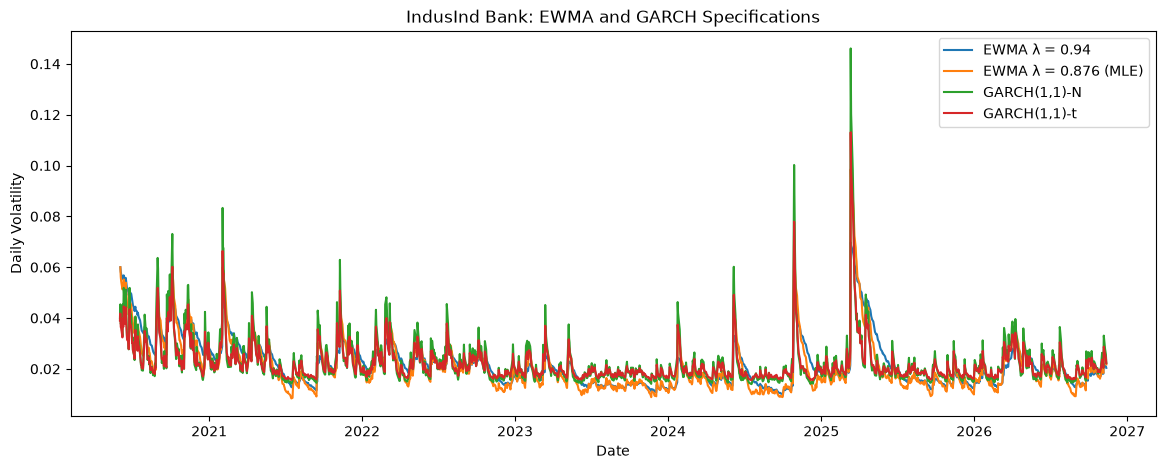

In [31]:
# [T2] EWMA and GARCH specifications compared
plt.figure(figsize=(14, 5))
plt.plot(ewma_vol, label=f"EWMA λ = {lam}")
plt.plot(ewma_vol_mle, label=f"EWMA λ = {lam_mle:.3f} (MLE)")
plt.plot(garch_vol, label="GARCH(1,1)-N")
plt.plot(garch_t_vol, label="GARCH(1,1)-t")
plt.title("IndusInd Bank: EWMA and GARCH Specifications")
plt.xlabel("Date")
plt.ylabel("Daily Volatility")
plt.legend()
plt.show()

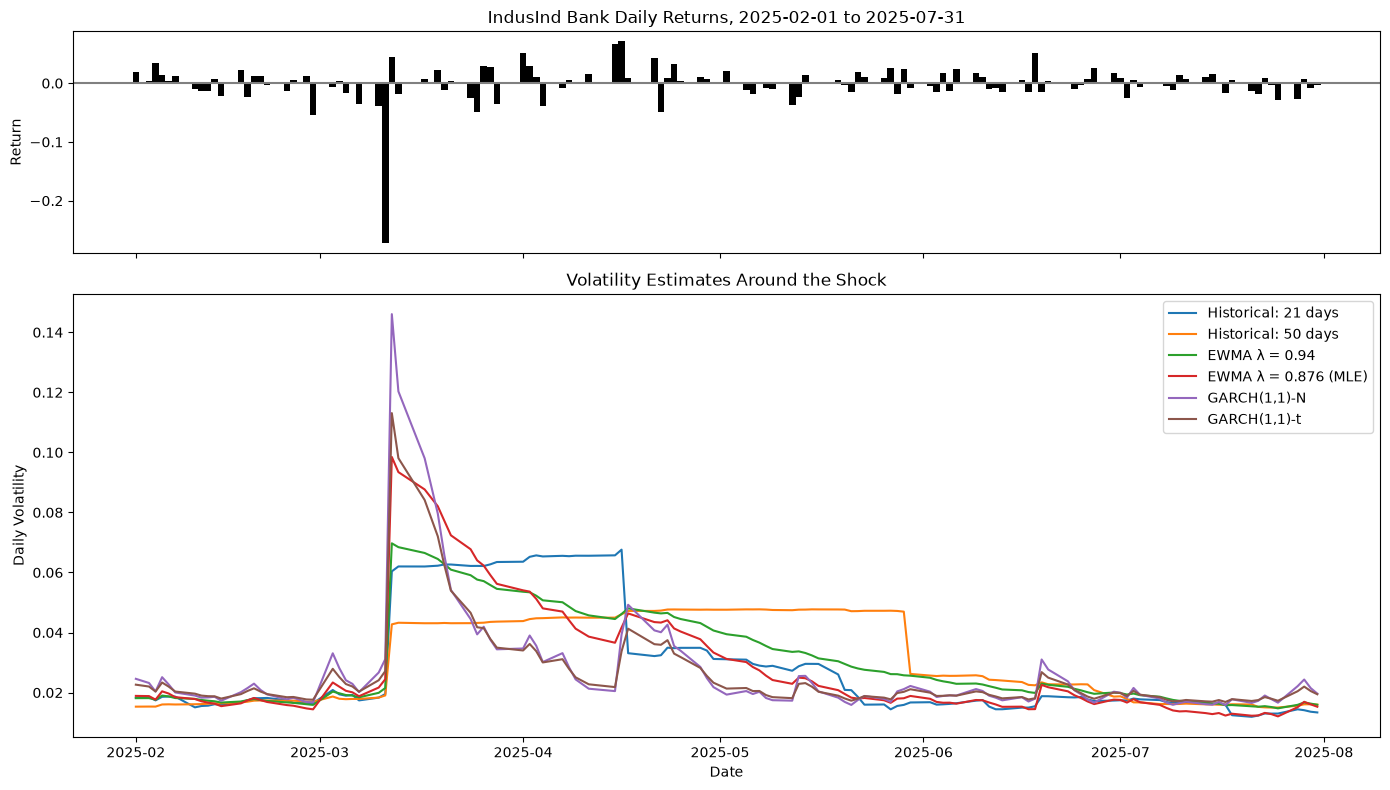

In [32]:
# [T2] crash window zoom
vol_estimators = {
    "Historical: 21 days": historical_vols[21],
    "Historical: 50 days": historical_vols[50],
    f"EWMA λ = {lam}": ewma_vol,
    f"EWMA λ = {lam_mle:.3f} (MLE)": ewma_vol_mle,
    "GARCH(1,1)-N": garch_vol,
    "GARCH(1,1)-t": garch_t_vol,
}

def plot_zoom(start, end):
    r = returns.loc[start:end]
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
    axes[0].bar(r.index, r, color="black", width=1)
    axes[0].axhline(0, color="grey")
    axes[0].set_title(f"IndusInd Bank Daily Returns, {start} to {end}")
    axes[0].set_ylabel("Return")
    for name, s in vol_estimators.items():
        axes[1].plot(s.loc[start:end], label=name)
    axes[1].set_title("Volatility Estimates Around the Shock")
    axes[1].set_ylabel("Daily Volatility")
    axes[1].set_xlabel("Date")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_zoom("2025-02-01", "2025-07-31")

In [33]:
# [T2] crash reaction table
key_dates = ["2025-03-11", "2025-03-12", "2025-04-16", "2025-04-17", "2025-05-30", "2025-07-31"]
reaction = pd.DataFrame({name: s.reindex(pd.to_datetime(key_dates)) for name, s in vol_estimators.items()}).T
reaction.columns = key_dates
print(reaction.round(4))

                      2025-03-11  2025-03-12  2025-04-16  2025-04-17  \
Historical: 21 days       0.0195      0.0604      0.0676      0.0331   
Historical: 50 days       0.0190      0.0427      0.0461      0.0472   
EWMA λ = 0.94             0.0215      0.0697      0.0462      0.0480   
EWMA λ = 0.876 (MLE)      0.0244      0.0985      0.0417      0.0464   
GARCH(1,1)-N              0.0311      0.1461      0.0393      0.0492   
GARCH(1,1)-t              0.0271      0.1131      0.0337      0.0413   

                      2025-05-30  2025-07-31  
Historical: 21 days       0.0167      0.0134  
Historical: 50 days       0.0262      0.0160  
EWMA λ = 0.94             0.0256      0.0159  
EWMA λ = 0.876 (MLE)      0.0189      0.0153  
GARCH(1,1)-N              0.0222      0.0197  
GARCH(1,1)-t              0.0211      0.0194  


## Task 3: Historical VaR

In [34]:
# [T3] historical VaR
var_levels = {"90%": 10, "95%": 5, "99%": 1}
hist_var = pd.Series({lvl: -np.percentile(var_returns, p, method="linear") for lvl, p in var_levels.items()})

print("Historical VaR (% loss):")
print((hist_var * 100).round(3).to_string())

Historical VaR (% loss):
90%    2.362
95%    3.444
99%    5.061


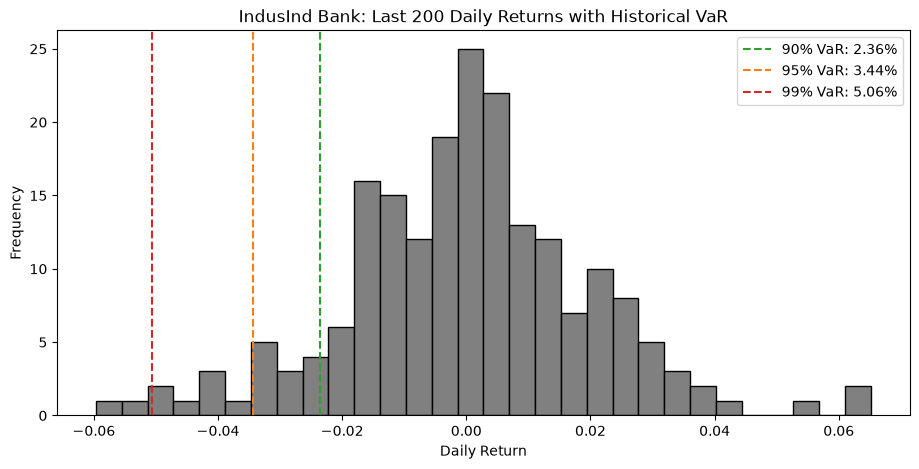

In [36]:
# [T3] historical VaR plot
plt.figure(figsize=(11, 5))
plt.hist(var_returns, bins=30, color="grey", edgecolor="black")
for (lvl, v), color in zip(hist_var.items(), ["tab:green", "tab:orange", "tab:red"]):
    plt.axvline(-v, color=color, linestyle="--", label=f"{lvl} VaR: {v * 100:.2f}%")
plt.title("IndusInd Bank: Last 200 Daily Returns with Historical VaR")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.legend()
plt.show()